### 1. Configuración de Entorno y Carga del Grid Horario
Cargamos las librerías necesarias y la matriz estructurada continua (`hourly_balance_2023.parquet`), donde cada registro representa una estación en una hora específica del año 2023.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)

# Rutas del proyecto
PROJECT_ROOT = Path('..').resolve() if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
DATA_INTERIM = PROJECT_ROOT / 'data' / 'interim'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Carga del grid horario 2023
df_hourly = pd.read_parquet(DATA_INTERIM / 'hourly_balance_2023.parquet')

# Si las dimensiones temporales están en el índice, las pasamos a columnas
if 'station_id' not in df_hourly.columns:
    df_hourly = df_hourly.reset_index()

print("Columnas disponibles:", df_hourly.columns.tolist())
print(f"Dimensiones del dataset: {df_hourly.shape[0]:,} filas x {df_hourly.shape[1]} columnas")
print(f"Rango temporal: {df_hourly['timestamp'].min()} a {df_hourly['timestamp'].max()}")

# Identificamos el nombre de la columna de estación (station_id o similar)
station_col = [c for c in df_hourly.columns if 'station' in c.lower() or 'id' in c.lower()][0]
print(f"Estaciones monitoreadas ({station_col}): {df_hourly[station_col].nunique()}")

df_hourly.head()

Columnas disponibles: ['index', 'estacion_id', 'timestamp', 'salidas', 'entradas', 'balance']
Dimensiones del dataset: 3,144,840 filas x 6 columnas
Rango temporal: 2023-01-01 00:00:00 a 2023-12-31 23:00:00
Estaciones monitoreadas (estacion_id): 359


,index,estacion_id,timestamp,salidas,entradas,balance
0,0,2,2023-01-01 00:00:00,0,0,0
1,1,2,2023-01-01 01:00:00,0,0,0
2,2,2,2023-01-01 02:00:00,0,0,0
3,3,2,2023-01-01 03:00:00,0,0,0
4,4,2,2023-01-01 04:00:00,0,0,0


### 2. Estadísticas Globales y Nivel de Esparcimiento (Sparsity)
Evaluamos el volumen total anual de viajes y la proporción de horas sin actividad por estación para entender la densidad de la demanda.

In [3]:
# Estadísticas globales de flujo anual
total_entradas = df_hourly['entradas'].sum()
total_salidas = df_hourly['salidas'].sum()
mean_entradas_hour = df_hourly['entradas'].mean()
mean_salidas_hour = df_hourly['salidas'].mean()

# Proporción de horas sin actividad en la estación (esparcimiento)
sparsity = (df_hourly['entradas'] == 0) & (df_hourly['salidas'] == 0)

print(f"Total de Entradas registradas: {int(total_entradas):,}")
print(f"Total de Salidas registradas:  {int(total_salidas):,}")
print(f"Promedio Entradas / Estación-Hora: {mean_entradas_hour:.4f}")
print(f"Promedio Salidas / Estación-Hora:  {mean_salidas_hour:.4f}")
print(f"Porcentaje de Horas Inactivas (Sin flujo): {sparsity.mean() * 100:.2f}%")

df_hourly[['entradas', 'salidas', 'balance']].describe()

Total de Entradas registradas: 3,908,646
Total de Salidas registradas:  3,908,646
Promedio Entradas / Estación-Hora: 1.2429
Promedio Salidas / Estación-Hora:  1.2429
Porcentaje de Horas Inactivas (Sin flujo): 53.15%


,entradas,salidas,balance
count,3.144840e+06,3.144840e+06,3.144840e+06
mean,1.242876e+00,1.242876e+00,0.000000e+00
std,2.607910e+00,2.494240e+00,1.834672e+00
min,0.000000e+00,0.000000e+00,-7.600000e+01
25%,0.000000e+00,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.000000e+00,2.000000e+00,0.000000e+00
max,1.090000e+02,9.100000e+01,8.200000e+01


### 3. Patrones Temporales de Demanda y Horas Pico
Analizamos la distribución horaria promedio a lo largo de las 24 horas del día, comparando el comportamiento bimodal de días laborales (picos de 07:00–09:00 y 18:00–20:00) frente a fines de semana.

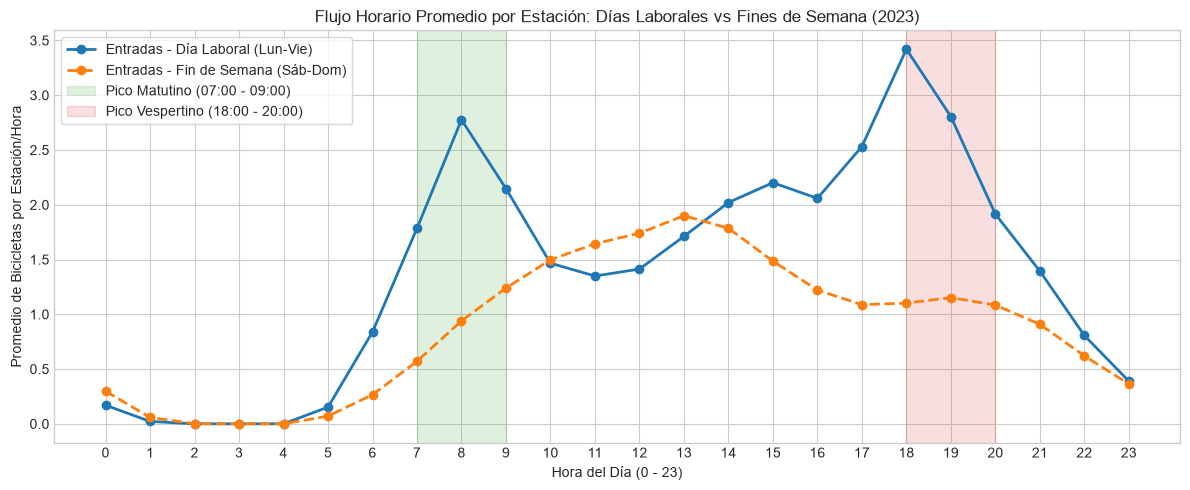

In [4]:
# Extraer variables temporales si no existen como columnas
df_hourly['hora'] = df_hourly['timestamp'].dt.hour
df_hourly['dia_semana'] = df_hourly['timestamp'].dt.dayofweek
df_hourly['es_fin_semana'] = df_hourly['dia_semana'].isin([5, 6]).astype(int)

# Agrupación horaria promedio por tipo de día
hourly_trend = df_hourly.groupby(['hora', 'es_fin_semana'])[['entradas', 'salidas']].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))

# Graficar días laborales vs fin de semana
for es_wknd, label, color, style in [
    (0, 'Día Laboral (Lun-Vie)', '#1f77b4', '-'),
    (1, 'Fin de Semana (Sáb-Dom)', '#ff7f0e', '--')
]:
    sub = hourly_trend[hourly_trend['es_fin_semana'] == es_wknd]
    ax.plot(sub['hora'], sub['entradas'], label=f'Entradas - {label}', color=color, linestyle=style, marker='o', linewidth=2)

ax.set_title('Flujo Horario Promedio por Estación: Días Laborales vs Fines de Semana (2023)')
ax.set_xlabel('Hora del Día (0 - 23)')
ax.set_ylabel('Promedio de Bicicletas por Estación/Hora')
ax.set_xticks(range(0, 24))

# Resaltar picos laborales
ax.axvspan(7, 9, color='#2ca02c', alpha=0.15, label='Pico Matutino (07:00 - 09:00)')
ax.axvspan(18, 20, color='#d62728', alpha=0.15, label='Pico Vespertino (18:00 - 20:00)')

ax.legend(frameon=True, loc='upper left')
plt.tight_layout()

# Guardar figura para el reporte
plt.savefig(FIGURES_DIR / '01_flujo_horario_pico.png', dpi=300)
plt.show()

### 4. Demanda Total Anual por Día de la Semana
Comparamos el volumen agregado de viajes por día para identificar la concentración de uso de lunes a viernes vs. la disminución en fines de semana.


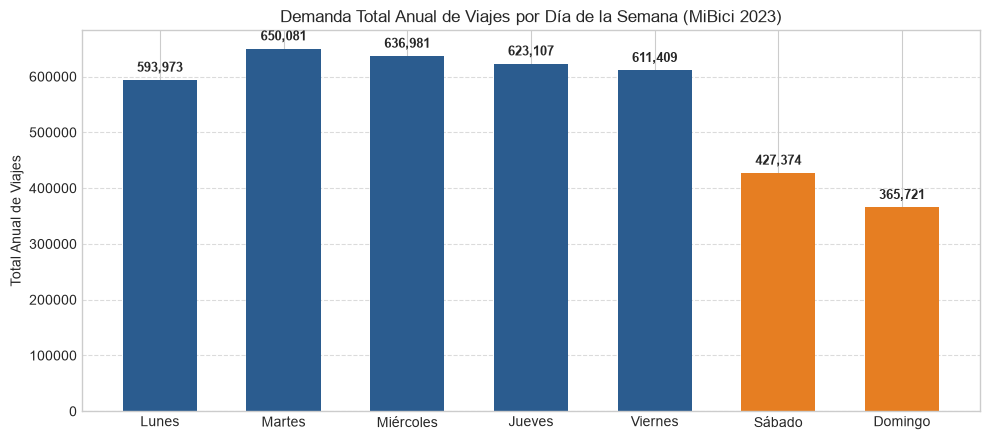

In [5]:
# Mapeo de días de la semana (0 = Lunes, 6 = Domingo)
dias_map = {0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves', 4: 'Viernes', 5: 'Sábado', 6: 'Domingo'}
daily_demand = df_hourly.groupby('dia_semana')['entradas'].sum().reset_index()
daily_demand['nombre_dia'] = daily_demand['dia_semana'].map(dias_map)

fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ['#2b5c8f' if d < 5 else '#e67e22' for d in daily_demand['dia_semana']]
bars = ax.bar(daily_demand['nombre_dia'], daily_demand['entradas'], color=colores, width=0.6)

ax.set_title('Demanda Total Anual de Viajes por Día de la Semana (MiBici 2023)')
ax.set_ylabel('Total Anual de Viajes')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Anotaciones numéricas sobre cada barra
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height):,}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_demanda_dia_semana.png', dpi=300)
plt.show()

### 5. Estaciones Críticas: Ranking de Mayor Desbalance
Identificamos las estaciones con mayor desbalance horario absoluto acumulado ($|Entradas - Salidas|$), que representan los puntos con mayor urgencia de rebalanceo logístico.

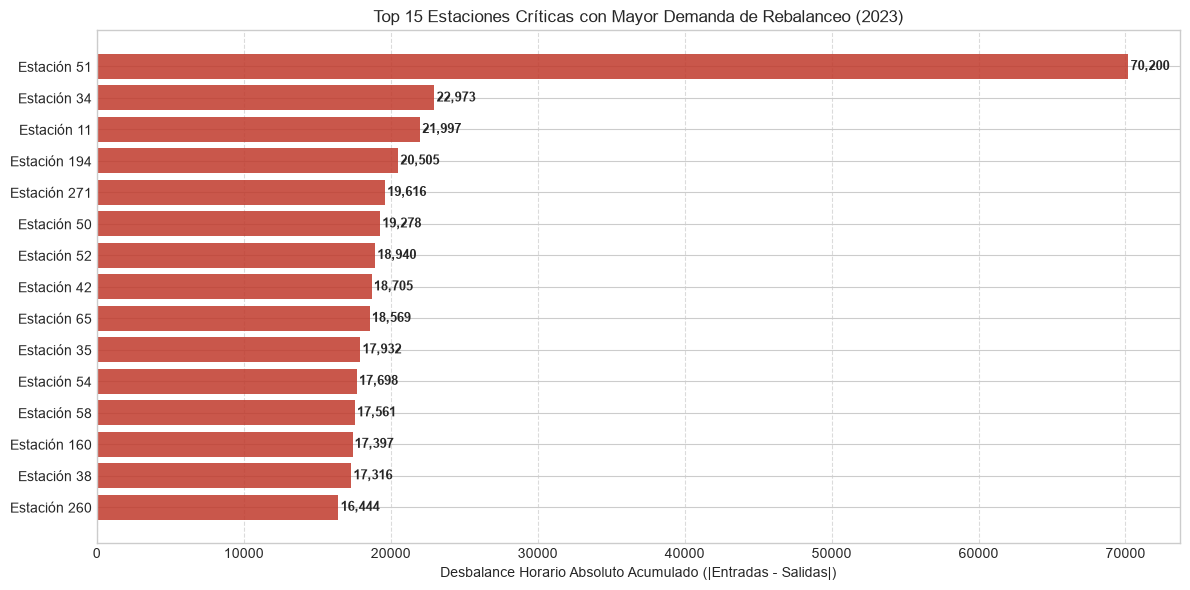

,estacion_id,total_entradas,total_salidas,balance_neto,desbalance_absoluto
47,51,106313,87499,18814,70200
30,34,47182,33119,14063,22973
8,11,57644,61671,-4027,21997
175,194,24739,37912,-13173,20505
248,271,58453,60605,-2152,19616


In [6]:
# Estadísticas acumuladas por estación
station_stats = df_hourly.groupby('estacion_id').agg(
    total_entradas=('entradas', 'sum'),
    total_salidas=('salidas', 'sum'),
    balance_neto=('balance', 'sum'),
    desbalance_absoluto=('balance', lambda x: np.abs(x).sum())
).reset_index()

# Top 15 estaciones con mayor desbalance absoluto
top_imbalance = station_stats.sort_values(by='desbalance_absoluto', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 6))
y_pos = np.arange(len(top_imbalance))

ax.barh(y_pos, top_imbalance['desbalance_absoluto'], color='#c0392b', alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels([f"Estación {int(sid)}" for sid in top_imbalance['estacion_id']])
ax.invert_yaxis()  # La de mayor desbalance arriba
ax.set_xlabel('Desbalance Horario Absoluto Acumulado (|Entradas - Salidas|)')
ax.set_title('Top 15 Estaciones Críticas con Mayor Demanda de Rebalanceo (2023)')
ax.grid(axis='x', linestyle='--', alpha=0.7)

# Anotación sobre las barras
for i, v in enumerate(top_imbalance['desbalance_absoluto']):
    ax.text(v + 150, i, f"{int(v):,}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_top_estaciones_desbalance.png', dpi=300)
plt.show()

# Mostrar la tabla de las top 5 estaciones críticas
top_imbalance.head()

### 6. Dinámica Pendular en Estación Crítica (Estación 51)
Analizamos la curva de 24 horas de la Estación 51 en días laborales para observar el flujo pendular: déficit matutino (requiere inyección de bicicletas) y superávit vespertino (requiere retiro de bicicletas).

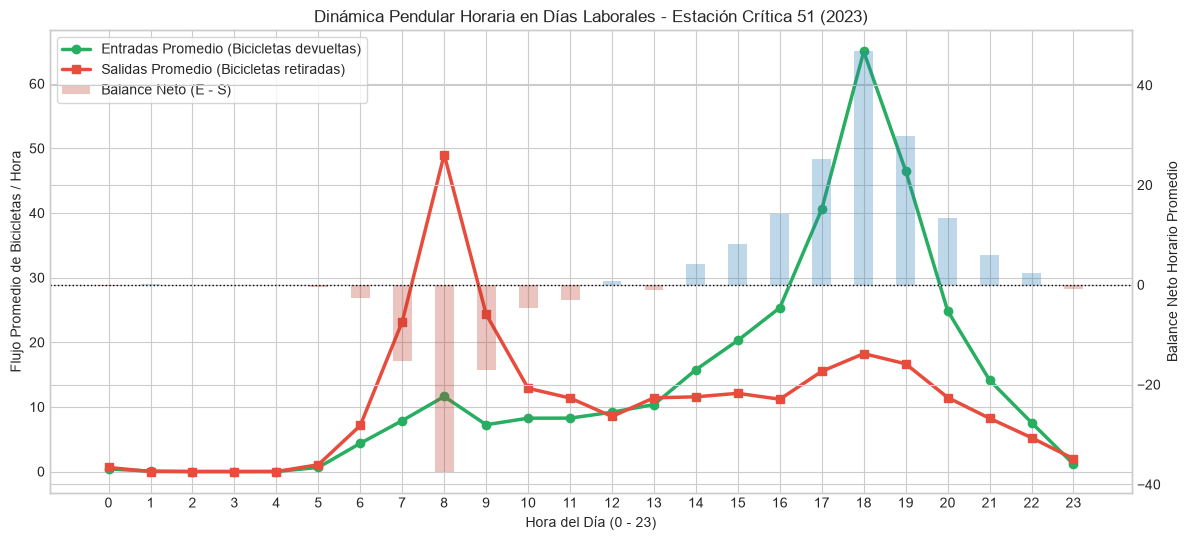

In [7]:
# Filtrar los datos para la Estación 51
df_estacion_51 = df_hourly[df_hourly['estacion_id'] == 51]

# Promedio por hora del día en días laborales
df_estacion_51_lab = df_estacion_51[df_estacion_51['es_fin_semana'] == 0]
hourly_51 = df_estacion_51_lab.groupby('hora')[['entradas', 'salidas', 'balance']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5.5))

# Eje 1: Entradas y Salidas promedio
ax1.plot(hourly_51['hora'], hourly_51['entradas'], color='#27ae60', marker='o', linewidth=2.5, label='Entradas Promedio (Bicicletas devueltas)')
ax1.plot(hourly_51['hora'], hourly_51['salidas'], color='#e74c3c', marker='s', linewidth=2.5, label='Salidas Promedio (Bicicletas retiradas)')
ax1.set_xlabel('Hora del Día (0 - 23)')
ax1.set_ylabel('Flujo Promedio de Bicicletas / Hora')
ax1.set_xticks(range(0, 24))
ax1.set_title('Dinámica Pendular Horaria en Días Laborales - Estación Crítica 51 (2023)')

# Eje 2: Balance Neto (Entradas - Salidas)
ax2 = ax1.twinx()
bar_colors = ['#2980b9' if b >= 0 else '#c0392b' for b in hourly_51['balance']]
ax2.bar(hourly_51['hora'], hourly_51['balance'], color=bar_colors, alpha=0.3, width=0.45, label='Balance Neto (E - S)')
ax2.axhline(0, color='black', linestyle=':', linewidth=1)
ax2.set_ylabel('Balance Neto Horario Promedio')

# Combinar leyendas de ambos ejes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_dinamica_estacion_51.png', dpi=300)
plt.show()

### 7. Validación de Ingeniería de Características (Features) y Correlaciones
Cargamos el dataset procesado con variables temporales, lags ($t-1\text{h}, t-24\text{h}, t-168\text{h}$) y medias móviles para evaluar su correlación con la demanda real.

Dataset de Features: 3,084,528 filas x 33 columnas
Columnas de features: ['estacion_id', 'timestamp', 'salidas', 'entradas', 'balance', 'mes', 'dia_mes', 'dia_semana', 'hora', 'es_fin_de_semana', 'es_hora_pico', 'hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos'] ...


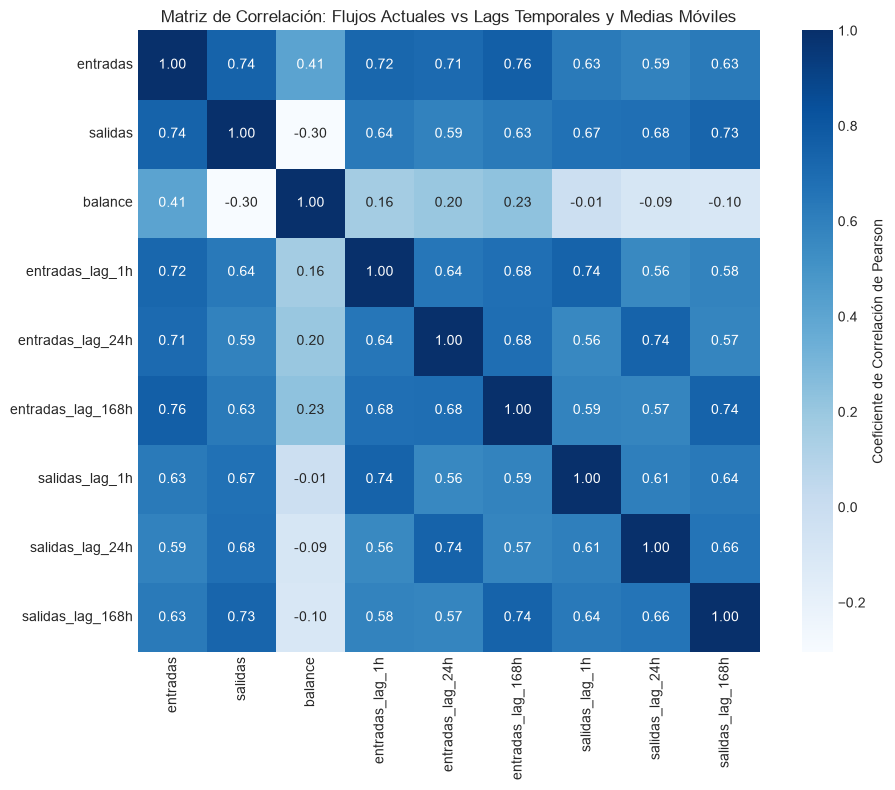

In [8]:
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
features_path = DATA_PROCESSED / 'features_2023.parquet'

if features_path.exists():
    df_features = pd.read_parquet(features_path)
    print(f"Dataset de Features: {df_features.shape[0]:,} filas x {df_features.shape[1]} columnas")
    print("Columnas de features:", df_features.columns.tolist()[:15], "...")
    
    # Seleccionar columnas clave de demanda y lags para correlación
    # Filtramos las columnas que existan en el DataFrame
    candidate_cols = [
        'entradas', 'salidas', 'balance',
        'entries', 'exits',
        'entradas_lag_1h', 'entradas_lag_24h', 'entradas_lag_168h',
        'salidas_lag_1h', 'salidas_lag_24h', 'salidas_lag_168h',
        'entries_lag_1h', 'entries_lag_24h', 'exits_lag_1h', 'exits_lag_24h',
        'entradas_media_movil_6h', 'salidas_media_movil_6h',
        'entries_rolling_mean_6h', 'exits_rolling_mean_6h'
    ]
    corr_cols = [c for c in candidate_cols if c in df_features.columns]
    
    corr_matrix = df_features[corr_cols].corr()
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', square=True, cbar_kws={'label': 'Coeficiente de Correlación de Pearson'})
    plt.title('Matriz de Correlación: Flujos Actuales vs Lags Temporales y Medias Móviles')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '05_matriz_correlacion_lags.png', dpi=300)
    plt.show()
else:
    print(f"Archivo no encontrado en {features_path}")